<a href="https://colab.research.google.com/github/antoine-bourgois/MIA_2026_UE16_NLP/blob/main/code/4_TFIDF_Classification_Avis_Goodreads.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## TP 4 : TFIDF Classification Avis Goodreads

- Chargement dataset
- Tokenisation
- Pré-traitement
- Représentation document sac de mots (BoW)
- Normalisation en fréquences
- TF-IDF
- Similarité cosinus entre documents
- Réduction de dimension
- Clustering

## 1. Configuration de l'environnement

### 1.1 Installation des dépendances et téléchargement du modèle spaCy
Installation des bibliothèques nécessaires pour la manipulation de données, le NLP et le machine learning, suivie du téléchargement du modèle anglais `en_core_web_sm`.

In [1]:
!pip install tqdm jupyter ipywidgets datasets pyarrow huggingface_hub pandas matplotlib numpy scipy scikit-learn umap-learn plotly spacy --quiet
! python -m spacy download en_core_web_sm --quiet


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
/home/antoine/cours/DAUPHINE_2026-2027/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1264: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
/home/antoine/cours/DAUPHINE_2026-2027/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1322: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12050). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  r = torch._C._cuda_getDeviceCount() if nvml_count < 0 else nvml_count

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install 

In [2]:
from tqdm.auto import tqdm
from collections import Counter

### 1.2 Importation des utilitaires et initialisation de spaCy
Chargement de `spacy` en désactivant les composants inutiles (`parser` et `ner`) afin d'accélérer le traitement lors de la tokenisation et de la lemmatisation.

In [3]:
import spacy
from tqdm import tqdm

nlp = spacy.load("en_core_web_sm", exclude=["parser", "ner"])


/home/antoine/cours/DAUPHINE_2026-2027/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1264: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
/home/antoine/cours/DAUPHINE_2026-2027/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1322: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12050). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  r = torch._C._cuda_getDeviceCount() if nvml_count < 0 else nvml_count


## 2. Chargement et préparation du dataset

### 2.1 Importation depuis Hugging Face
Chargement du jeu de données `AntoineBourgois/goodreads-books-reviews` et sélection de la partition d'entraînement.

In [4]:
from datasets import load_dataset
import pandas as pd

dataset = load_dataset("AntoineBourgois/goodreads-books-reviews")

train_dataset = dataset["train"]

print(train_dataset)

Dataset({
    features: ['user_id', 'book_id', 'review_id', 'rating', 'review_text', 'date_added', 'date_updated', 'read_at', 'started_at', 'n_votes', 'n_comments'],
    num_rows: 900000
})


### 2.2 Nettoyage et formatage des données
Conversion en DataFrame Pandas, conservation des colonnes `review_text` et `rating`, suppression des valeurs manquantes ou vides, mise en minuscules et troncature à 2 000 caractères maximum.

In [5]:
# Conversion en DataFrame
df = pd.DataFrame(train_dataset)

# Conservation des colonnes utiles
df = df[["review_text", "rating"]].copy()

# Suppression des valeurs manquantes
df = df.dropna(subset=["review_text", "rating"])

# Nettoyage du texte
df["review_text"] = df["review_text"].astype(str).str.lower().str.strip()

# Suppression des reviews vides
df = df[df["review_text"] != ""]

max_chars = 2000

df["review_text"] = df["review_text"].str[:max_chars]

print("Nombre de reviews :", len(df))
print(df.head())

Nombre de reviews : 900000
                                         review_text  rating
0  this is a special book. it started slow for ab...       5
1  recommended by don katz. avail for free in dec...       3
2  a fun, fast paced science fiction thriller. i ...       3
3  recommended reading to understand what is goin...       0
4  i really enjoyed this book, and there is a lot...       4


### 2.3 Équilibrage des classes (Sous-échantillonnage)
Pour éviter tout biais lié à une surreprésentation de certaines notes, on extrait un échantillon aléatoire de `n_samples` avis pour chaque note (de 0 à 5), puis on mélange aléatoirement le jeu de données résultant.

In [6]:
# Parameters
n_samples = 2500 # 25000
max_chars = 2000

REMOVE_0_RATINGS = False
if REMOVE_0_RATINGS:
    # Keep reviews with at most max_chars characters and exclude rating 0
    df = df[
        (df["review_text"].str.len() <= max_chars) &
        (df["rating"] != 0)
    ].copy()


# Keep reviews with at most max_chars characters
df_filtered = df[
    df["review_text"].str.len() <= max_chars
].copy()

print("Reviews after length filtering:", len(df_filtered))

# Random sampling for each rating
balanced_dfs = []

for rating in sorted(df_filtered["rating"].unique()):

    df_rating = df_filtered[df_filtered["rating"] == rating]

    df_sampled = df_rating.sample(
        n=n_samples,
        random_state=42
    )

    balanced_dfs.append(df_sampled)

# Concatenate samples
df_balanced = pd.concat(balanced_dfs, ignore_index=True)

# Shuffle dataset
df_balanced = df_balanced.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Check distribution
print(df_balanced["rating"].value_counts().sort_index())

print("Total reviews:", len(df_balanced))
print("Maximum review length:", df_balanced["review_text"].str.len().max())
print("Average review length:", df_balanced["review_text"].str.len().mean())

Reviews after length filtering: 900000
rating
0    2500
1    2500
2    2500
3    2500
4    2500
5    2500
Name: count, dtype: int64
Total reviews: 15000
Maximum review length: 2000
Average review length: 792.0212


In [7]:
df_balanced.head(10)

,review_text,rating
0,i received an earc of this book from netgalley...,4
1,** spoiler alert ** \n there are a lot of revi...,2
2,wonderful book. it was just as good as the fir...,5
3,i really wanted to love this but i thought the...,0
4,a reincarnation-centric tale set in a decrepit...,2
5,"i know i'm supposed to suspend my disbelief, b...",2
6,"i tried and i do mean tried to read this book,...",1
7,i read this for school. hated it. melodramatic...,1
8,first off; i did not finish this book (i've be...,1
9,i'm giving up. it's been four months. it's tim...,0


## 3. Prétraitement linguistique et séparation des données

### 3.1 Définition de la fonction de tokenisation et lemmatisation
Création de la fonction `get_tokens` utilisant `nlp.pipe` pour traiter les textes par lots : suppression des espaces, de la ponctuation et des mots vides (*stop words*), suivie de la lemmatisation.

In [8]:
from tqdm import tqdm

def get_tokens(
    data,
    remove_punctuation=True,
    remove_stop_words=True,
    lowercase=True,
    lemmatize=True,
    batch_size=256,
    n_process=4,
):

    def extract(doc):
        tokens = []

        for token in doc:
            if token.is_space:
                continue

            if remove_punctuation and token.is_punct:
                continue

            if remove_stop_words and token.is_stop:
                continue

            word = token.lemma_ if lemmatize else token.text

            if lowercase:
                word = word.lower()

            tokens.append(word)

        return tokens

    # Case 1: Single text
    if isinstance(data, str):
        return extract(nlp(data))

    # Case 2: Dictionary of documents
    if isinstance(data, dict):
        titles = list(data.keys())
        texts = (data[t]["text"] for t in titles)

        docs = nlp.pipe(
            texts,
            batch_size=batch_size,
            n_process=n_process
        )

        for title, doc in tqdm(zip(titles, docs), total=len(titles)):
            data[title]["tokens"] = extract(doc)

        return data

    # Case 3: List or Pandas Series of texts
    texts = list(data)

    docs = nlp.pipe(
        texts,
        batch_size=batch_size,
        n_process=n_process
    )

    tokens_list = [
        extract(doc)
        for doc in tqdm(docs, total=len(texts))
    ]

    return tokens_list

### 3.2 Séparation Train / Test et tokenisation des corpus
Découpage stratifié du dataset en ensembles d'entraînement (80 %) et de test (20 %) avant d'appliquer la tokenisation sur chaque sous-ensemble.

In [9]:
from sklearn.model_selection import train_test_split

X = df_balanced["review_text"]
y = df_balanced["rating"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", len(X_train_text))
print("Test:", len(X_test_text))

Train: 12000
Test: 3000


In [10]:
# Tokenization and lemmatization
X_train_tokens = get_tokens(X_train_text,
                            remove_punctuation=True,
                            remove_stop_words=True,
                            )

X_test_tokens = get_tokens(X_test_text,
                           remove_punctuation=True,
                           remove_stop_words=True,
                           )

100%|██████████| 3000/3000 [00:11<00:00, 250.30it/s]


## 4. Vectorisation TF-IDF

### 4.1 Calcul des matrices TF-IDF (Train et Test)
Transformation des listes de tokens en vecteurs numériques TF-IDF prenant en compte les unigrammes et bigrammes (`ngram_range=(1, 2)`). Le vectoriseur est ajusté uniquement sur `X_train_tokens` (`fit_transform`) puis appliqué sur `X_test_tokens` (`transform`) afin d'éviter toute fuite de données.

In [11]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

def compute_tfidf(
    documents,
    max_df=0.90,
    min_df=10,
    max_features=50000
):
    """
    Compute TF-IDF representations from tokenized documents.

    Parameters
    ----------
    documents : list
        List of tokenized documents.

    Returns
    -------
    vectorizer : TfidfVectorizer
        Fitted TF-IDF vectorizer.

    X_tfidf : sparse matrix
        TF-IDF matrix.
    """

    vectorizer = TfidfVectorizer(
        tokenizer=lambda x: x,
        preprocessor=None,
        token_pattern=None,
        lowercase=False,
        max_df=max_df,
        min_df=min_df,
        max_features=max_features,
        ngram_range=(2, 2)
    )

    X_tfidf = vectorizer.fit_transform(documents)

    return vectorizer, X_tfidf

In [12]:
vectorizer, X_train_tfidf = compute_tfidf(
    X_train_tokens,
    max_df=0.90,
    min_df=10,
    max_features=50000
)

print("Train TF-IDF:", X_train_tfidf.shape)

Train TF-IDF: (12000, 4886)


In [13]:
X_test_tfidf = vectorizer.transform(X_test_tokens)

print("Test TF-IDF:", X_test_tfidf.shape)

Test TF-IDF: (3000, 4886)


### 4.2 Inspection du vocabulaire et des poids TF-IDF
Vérification de la taille du vocabulaire extrait et affichage des 10 termes ayant les scores TF-IDF les plus élevés pour un premier avis d'exemple.

In [14]:
vocabulary = vectorizer.get_feature_names_out()

print("Vocabulary size:", len(vocabulary))
print("First 20 words:", vocabulary[:20])

Vocabulary size: 4886
First 20 words: ['+ page' '1 2' '1 book' '1 star' '1.5 star' '1/2 star' '10 book'
 '10 page' '10 year' '100 page' '11 year' '12 year' '13 year' '14 year'
 '15 year' '150 page' '16 year' '17 year' '18 year' '18th century']


In [15]:
doc_id = 0

# Retrieve TF-IDF vector
tfidf_vector = X_train_tfidf[doc_id].toarray().flatten()

# Get the 10 highest-scoring terms
top_indices = tfidf_vector.argsort()[-10:][::-1]

top_words = [
    (vocabulary[i], round(tfidf_vector[i], 4))
    for i in top_indices
    if tfidf_vector[i] > 0
]

print("Original review:")
print(X_train_text.iloc[doc_id])

print("\nTokens:")
print(X_train_tokens[doc_id])

top_words = [
    (vocabulary[i], float(round(tfidf_vector[i], 4)))
    for i in top_indices
    if tfidf_vector[i] > 0
]

print("\nTop TF-IDF words:")
print(top_words)

Original review:
overall, i enjoyed last year's mistake. it's a solid teen romance, and the drama between characters is very realistic. 
 i had a couple of issues with the plot structure, though. the story is told in alternating chapters between what happened two-four years prior and what was happening currently in kelsey's senior year. the way it's told and the way things are described are full of suspense - so much so that i kept expecting some big "mistake" - like some death or crime (i don't know, something like i know what you did last summer). even when the mistake was revealed (which wasn't "last year" as the title suggests), i didn't realize that was the big mistake until i went back and read the synopsis again. the suspense-building was fine, but the big reveal was lacking.

Tokens:
['overall', 'enjoy', 'year', 'mistake', 'solid', 'teen', 'romance', 'drama', 'character', 'realistic', 'couple', 'issue', 'plot', 'structure', 'story', 'tell', 'alternate', 'chapter', 'happen', 'ye

## 5. Entraînement et évaluation des modèles de classification

### 5.1 Régression Logistique (`LogisticRegression`)
Initialisation, entraînement et évaluation d'un modèle de régression logistique multi-classe, accompagnés de l'affichage de la matrice de confusion.

In [16]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    C=0.1,
    random_state=42
)

# Training
logistic_model.fit(X_train_tfidf, y_train)

print("Logistic Regression trained!")

Logistic Regression trained!


In [17]:
y_pred_lr = logistic_model.predict(X_test_tfidf)

print("First 20 predictions:")
print(y_pred_lr[:20])

First 20 predictions:
[0 0 0 1 1 4 3 3 5 4 1 3 0 0 4 3 5 5 5 1]


In [18]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))

print("\nClassification report:")
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.3757

Classification report:
              precision    recall  f1-score   support

           0       0.35      0.59      0.44       500
           1       0.42      0.40      0.41       500
           2       0.36      0.34      0.35       500
           3       0.36      0.26      0.30       500
           4       0.32      0.21      0.25       500
           5       0.44      0.46      0.45       500

    accuracy                           0.38      3000
   macro avg       0.37      0.38      0.37      3000
weighted avg       0.37      0.38      0.37      3000



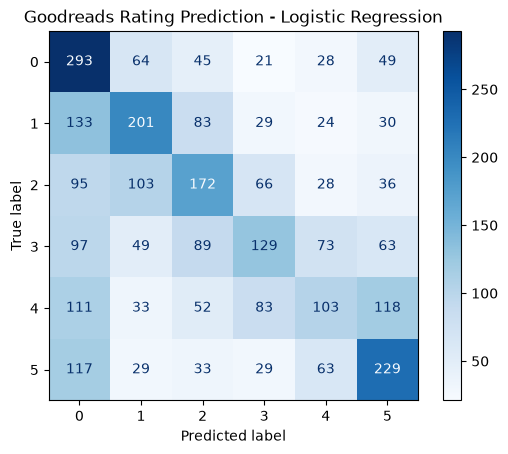

In [19]:
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=logistic_model.classes_
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Goodreads Rating Prediction - Logistic Regression")
plt.show()

### 5.2 Naive Bayes Multinomial (`MultinomialNB`)
Entraînement d'un classificateur bayésien naïf multinomial (particulièrement adapté aux représentations textuelles fréquentielles) et calcul de son rapport de classification.

In [20]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB(alpha=1.0)

nb_model.fit(X_train_tfidf, y_train)

y_pred_nb = nb_model.predict(X_test_tfidf)

print("Naive Bayes Accuracy:",
      round(accuracy_score(y_test, y_pred_nb), 4))

print(classification_report(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.3763
              precision    recall  f1-score   support

           0       0.41      0.46      0.43       500
           1       0.44      0.44      0.44       500
           2       0.35      0.34      0.34       500
           3       0.32      0.30      0.31       500
           4       0.28      0.24      0.26       500
           5       0.43      0.48      0.46       500

    accuracy                           0.38      3000
   macro avg       0.37      0.38      0.37      3000
weighted avg       0.37      0.38      0.37      3000



### 5.3 Machine à Vecteurs de Support Linéaire (`LinearSVC`)
Entraînement et évaluation d'un SVM linéaire sur les vecteurs TF-IDF.

In [21]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    C=1.0,
    max_iter=2000
)

svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)

print("Linear SVM Accuracy:",
      round(accuracy_score(y_test, y_pred_svm), 4))

print(classification_report(y_test, y_pred_svm))

Linear SVM Accuracy: 0.3463
              precision    recall  f1-score   support

           0       0.38      0.50      0.43       500
           1       0.39      0.36      0.37       500
           2       0.32      0.32      0.32       500
           3       0.31      0.29      0.30       500
           4       0.25      0.23      0.24       500
           5       0.41      0.39      0.40       500

    accuracy                           0.35      3000
   macro avg       0.34      0.35      0.34      3000
weighted avg       0.34      0.35      0.34      3000



### 5.4 Comparaison visuelle de l'exactitude (Accuracy)
Synthèse et représentation graphique des performances des trois premiers classificateurs.

In [22]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Linear SVM"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_svm)
    ]
})

results = results.sort_values(
    by="Accuracy",
    ascending=False
)

print(results)

                 Model  Accuracy
1          Naive Bayes  0.376333
0  Logistic Regression  0.375667
2           Linear SVM  0.346333


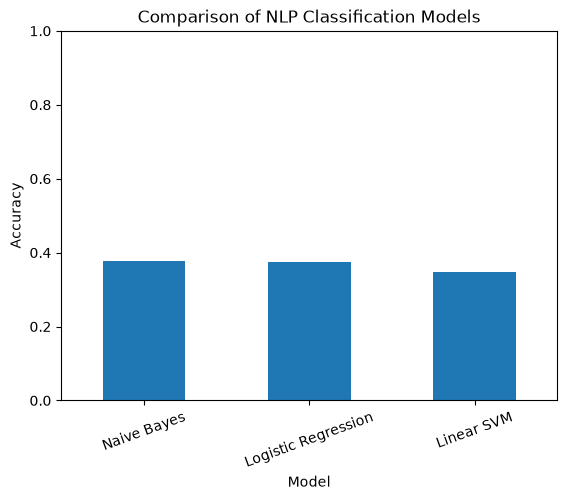

In [23]:
results.plot(
    x="Model",
    y="Accuracy",
    kind="bar",
    legend=False
)

plt.title("Comparison of NLP Classification Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.show()

### 5.5 Classificateur Ridge (`RidgeClassifier`) et métriques d'erreur
Comme les notes ont un caractère ordinal (0 à 5), l'exactitude seule ne reflète pas l'ampleur des erreurs. On ajoute un `RidgeClassifier` et on compare l'ensemble des modèles selon l'erreur absolue moyenne (**MAE**) et l'erreur quadratique moyenne (**MSE**).

In [24]:
from sklearn.linear_model import RidgeClassifier
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error

# Création du classificateur linéaire
ridge_model = RidgeClassifier(alpha=1.0)

# Entraînement du modèle
ridge_model.fit(X_train_tfidf, y_train)

# Prédiction des notes
y_pred_ridge = ridge_model.predict(X_test_tfidf)

# Évaluation du modèle
print("Accuracy :", round(accuracy_score(y_test, y_pred_ridge), 4))
print("MAE      :", round(mean_absolute_error(y_test, y_pred_ridge), 4))
print("MSE      :", round(mean_squared_error(y_test, y_pred_ridge), 4))

Accuracy : 0.3537
MAE      : 1.3423
MSE      : 3.8377


In [25]:
# Génération des prédictions pour chaque modèle
y_pred = logistic_model.predict(X_test_tfidf)
y_pred_nb = nb_model.predict(X_test_tfidf)
y_pred_svm = svm_model.predict(X_test_tfidf)
y_pred_ridge = ridge_model.predict(X_test_tfidf)

In [26]:
import pandas as pd
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error

# Liste des modèles et de leurs prédictions
predictions = {
    "Logistic Regression": y_pred,
    "Naive Bayes": y_pred_nb,
    "Linear SVM": y_pred_svm,
    "Ridge Classifier": y_pred_ridge
}

# Calcul des métriques pour chaque modèle
results = []

for model_name, predictions_model in predictions.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions_model),
        "MAE": mean_absolute_error(y_test, predictions_model),
        "MSE": mean_squared_error(y_test, predictions_model)
    })

# Création et affichage du tableau comparatif
results_df = pd.DataFrame(results)
print(results_df.sort_values("MAE"))

                 Model  Accuracy       MAE       MSE
1          Naive Bayes  0.376333  1.271667  3.623667
0  Logistic Regression  0.375667  1.336333  3.983000
3     Ridge Classifier  0.353667  1.342333  3.837667
2           Linear SVM  0.346333  1.367000  3.923667


### 5.6 Inférence sur un avis personnalisé
Définition d'une fonction utilitaire `predict_rating` permettant d'appliquer l'ensemble du pipeline (tokenisation, transformation TF-IDF et prédiction) sur n'importe quel nouveau texte.

In [27]:
def predict_rating(review, model):

    # Tokenization
    tokens = get_tokens(review)

    # TF-IDF transformation
    tfidf = vectorizer.transform([tokens])

    # Prediction
    prediction = model.predict(tfidf)

    return prediction[0]

In [28]:
review = """
This book was pretty good.
The characters were incredibly interesting,
The story was beautiful and I loved every page.
But the plot was quite bad.
"""

print("Predicted rating:", predict_rating(review, model=nb_model))

Predicted rating: 5


## 6. Approche par régression et analyse exploratoire des termes

### 6.1 Régression linéaire régularisée (`Ridge`)
Prédiction des notes sous forme de valeurs continues plutôt que de classes discrètes, suivie d'une visualisation par boîtes à moustaches (*boxplots*) comparant les prédictions aux notes réelles.

In [29]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Création du modèle de régression linéaire
regression_model = Ridge(alpha=1.0)

# Entraînement sur les représentations TF-IDF
regression_model.fit(X_train_tfidf, y_train)

# Prédiction des notes sous forme de valeurs continues
y_pred_continuous = regression_model.predict(X_test_tfidf)

# Évaluation des prédictions
mae = mean_absolute_error(y_test, y_pred_continuous)
mse = mean_squared_error(y_test, y_pred_continuous)
rmse = np.sqrt(mse)

print("MAE :", round(mae, 4))
print("MSE :", round(mse, 4))
print("RMSE:", round(rmse, 4))

MAE : 1.2584
MSE : 2.3857
RMSE: 1.5446


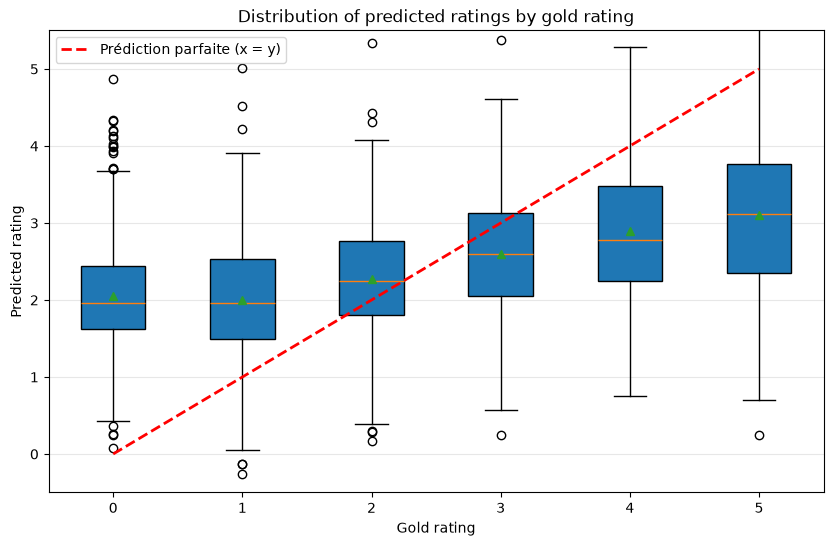

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# Regroupement des prédictions selon la note réelle
data = [
    y_pred_continuous[np.asarray(y_test) == rating]
    for rating in range(6)
]

# Création du boxplot
plt.figure(figsize=(10, 6))

plt.boxplot(
    data,
    tick_labels=range(6),
    patch_artist=True,
    showmeans=True
)

# Ajout de la diagonale correspondant aux prédictions parfaites
plt.plot(
    range(1, 7),
    range(6),
    "r--",
    linewidth=2,
    label="Prédiction parfaite (x = y)"
)

plt.xlabel("Gold rating")
plt.ylabel("Predicted rating")
plt.title("Distribution of predicted ratings by gold rating")

plt.xticks(range(1, 7), range(6))
plt.ylim(-0.5, 5.5)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.show()

### 6.2 Identification des mots les plus caractéristiques par note
Calcul d'un score de spécificité (fréquence relative dans une catégorie pondérée par la rareté dans les autres catégories) afin de visualiser les 10 termes les plus discriminants pour chaque note (0 à 5).

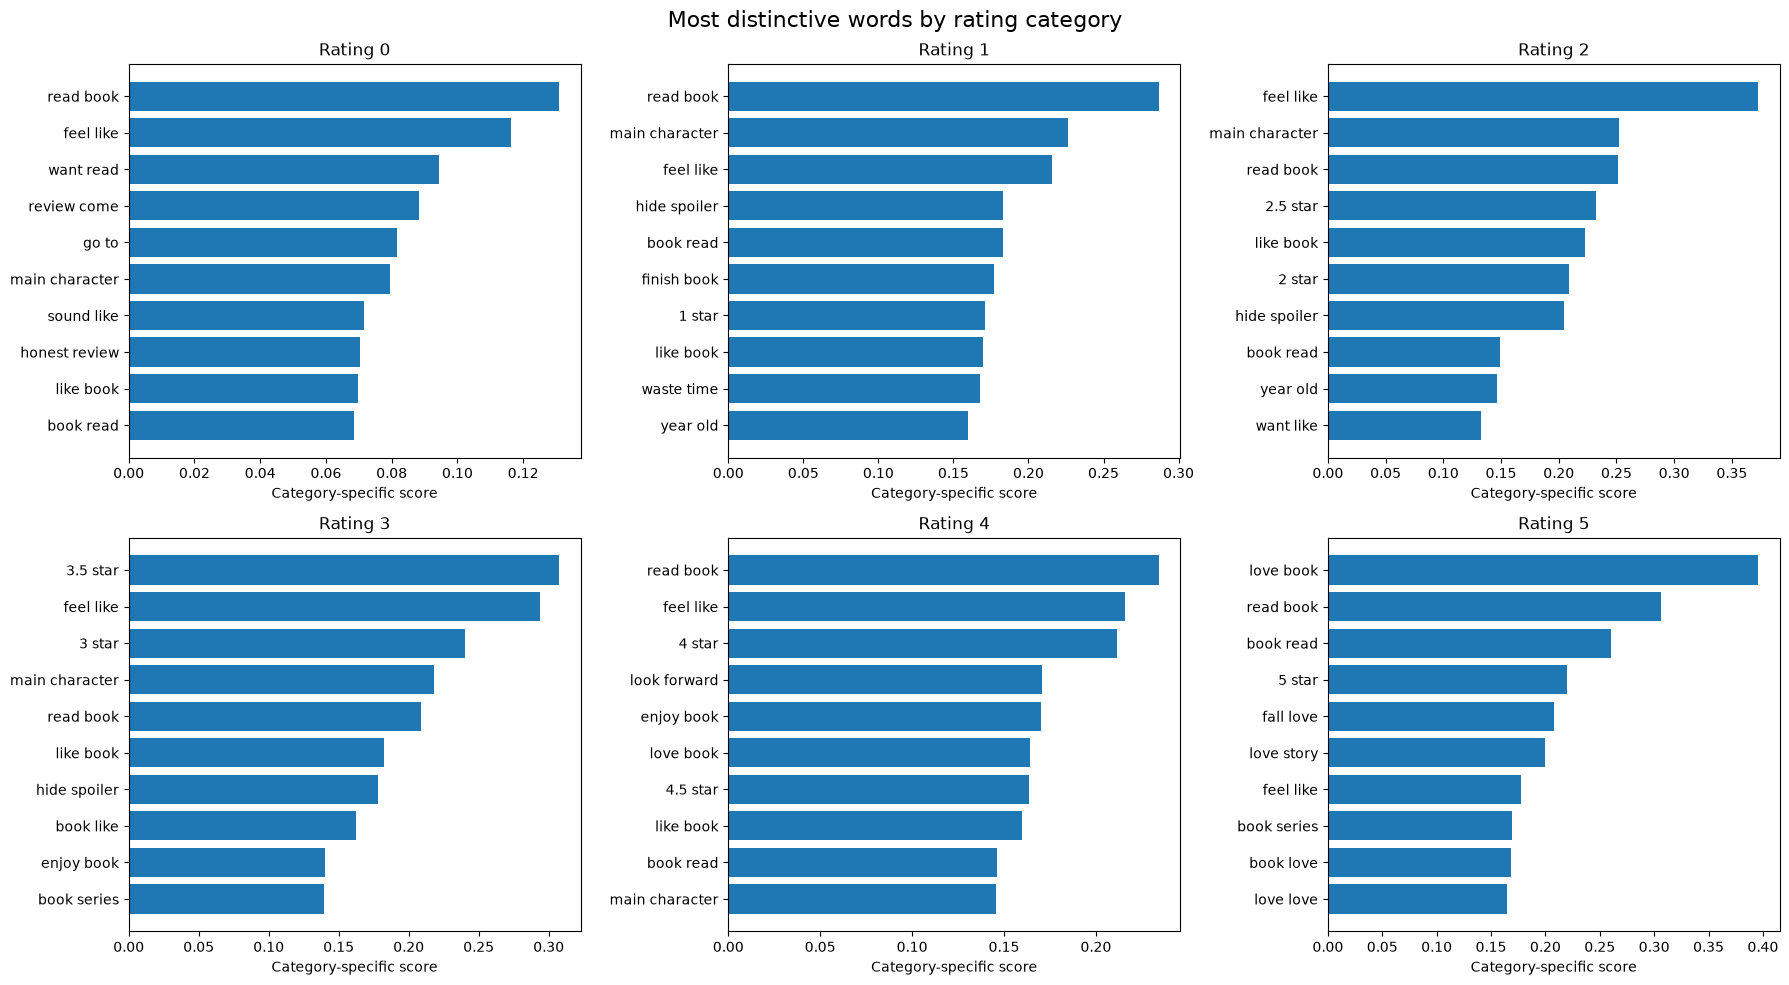

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Récupération du vocabulaire
vocabulary = vectorizer.get_feature_names_out()

# Conversion des notes en tableau NumPy
y_train_array = np.asarray(y_train)

# Nombre total de documents
n_documents = X_train_tfidf.shape[0]

# Calcul de la présence des termes dans chaque document
X_binary = (X_train_tfidf > 0).astype(int)

# Création de la figure
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for rating, ax in enumerate(axes.flatten()):

    # Sélection des documents de la catégorie étudiée
    mask_category = y_train_array == rating

    # Sélection des documents des autres catégories
    mask_other = y_train_array != rating

    X_category = X_binary[mask_category]
    X_other = X_binary[mask_other]

    # Nombre de documents contenant chaque terme dans chaque groupe
    df_category = np.asarray(X_category.sum(axis=0)).ravel()
    df_other = np.asarray(X_other.sum(axis=0)).ravel()

    # Fréquence relative des termes dans la catégorie
    tf_category = df_category / mask_category.sum()

    # Poids basé sur la rareté du terme dans les autres catégories
    idf_other = np.log(
        (mask_other.sum() + 1) / (df_other + 1)
    )

    # Calcul du score spécifique à la catégorie
    scores = tf_category * idf_other

    # Sélection des 10 termes les plus caractéristiques
    top_indices = scores.argsort()[-10:][::-1]

    top_words = vocabulary[top_indices]
    top_scores = scores[top_indices]

    # Affichage des résultats
    ax.barh(top_words[::-1], top_scores[::-1])
    ax.set_title(f"Rating {rating}")
    ax.set_xlabel("Category-specific score")

plt.suptitle("Most distinctive words by rating category", fontsize=16)
plt.tight_layout()
plt.show()

### 6.3 Rappel du classement des modèles
Affichage final du tableau récapitulatif trié par **MAE** croissante avant d'aborder l'optimisation des hyperparamètres.

In [32]:
print(f"BEST MAE: {min(results_df['MAE']):.4}")
print("------------------")
print(results_df.sort_values("MAE"))

BEST MAE: 1.272
------------------
                 Model  Accuracy       MAE       MSE
1          Naive Bayes  0.376333  1.271667  3.623667
0  Logistic Regression  0.375667  1.336333  3.983000
3     Ridge Classifier  0.353667  1.342333  3.837667
2           Linear SVM  0.346333  1.367000  3.923667


## 7. Exercice : Réduire la MAE du meilleur modèle

### Pistes d'amélioration :
- **Tokenizer / Prétraitement** : conserver la négation (ex. *not*, *no*), tester avec ou sans lemmatisation, ou ajuster le filtrage des *stop words*.
- **TF-IDF** : modifier `ngram_range` (ex. `(1, 3)`), `min_df`, `max_df`, `max_features`.
- **Hyperparamètres du modèle** : ajuster la régularisation (`C` pour la régression logistique / SVM, `alpha` pour Ridge / Naive Bayes) ou tester des seuils d'arrondi sur la régression continue.

In [33]:
df_balanced

,review_text,rating
0,i received an earc of this book from netgalley...,4
1,** spoiler alert ** \n there are a lot of revi...,2
2,wonderful book. it was just as good as the fir...,5
3,i really wanted to love this but i thought the...,0
4,a reincarnation-centric tale set in a decrepit...,2
...,...,...
14995,aria's issue was too drawn out. that kind of i...,2
14996,awesome new world for me! i loved this! i can'...,5
14997,"it was happy, happy times with the lovebirds. ...",2
14998,i just couldn't get into this heyer (the secon...,0
